# Modelo Final (testes e explicabilidade)

Este notebook parte do modelo **registrado no MLflow** no notebook 2 (`nuvemshop-fraud@champion`), sem retreinar:

1. carrega o modelo e o threshold de decisão do run de registro;
2. salva uma cópia do artefato em `models/logreg_champion.pkl`, para uso fora do MLflow;
3. reproduz as métricas por split e a **curva de custo** por threshold;
4. interpreta os **coeficientes**.

Requer o servidor de tracking local rodando (ver notebook 2).

In [1]:
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from mlflow.tracking import MlflowClient

sys.path.append("../")

from utils.metrics import classification_metrics
from utils.plots import plot_model_results
from utils.pnl import decision_pnl, optimal_threshold, threshold_cost_curve

import warnings

warnings.filterwarnings("ignore")

2026/10/12 23:16:17 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /home/bruno/nuvemshop_case/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## Carregamento do modelo do MLflow

In [2]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
client = MlflowClient()

champion_name = "nuvemshop-fraud"
version = client.get_model_version_by_alias(champion_name, "champion")
run = client.get_run(version.run_id)

model = mlflow.sklearn.load_model(f"models:/{champion_name}@champion")
features = run.data.params["features"].split(",")
threshold = float(run.data.params["decision_threshold"])
pnl_params = {"chargeback_fee": float(run.data.params["chargeback_fee"]),
              "margin": float(run.data.params["margin"])}

print(f"{champion_name} v{version.version} (run {version.run_id})")
print(f"features: {features}")
print(f"threshold: {threshold:.6f}")

nuvemshop-fraud v1 (run 1b9bb517b06f4dd09679a5e026101d05)
features: ['high_amount', 'night', 'risk_vertical', 'txns_prev_1h', 'amount_to_customer_median_ratio_30d_gt_5', 'n_high_prev_24h']
threshold: 0.085034


Cópia local do artefato, versionável junto ao repositório e utilizável sem o servidor de tracking:

In [3]:
model_path = Path("../models/logreg_champion.pkl")
model_path.parent.mkdir(exist_ok=True)
with open(model_path, "wb") as f:
    pickle.dump({"model": model, "features": features, "threshold": threshold,
                 "pnl_params": pnl_params, "mlflow_version": version.version}, f)
model_path.resolve()

PosixPath('/home/bruno/nuvemshop_case/models/logreg_champion.pkl')

## Dados e split

Mesma preparação e mesmo split temporal do notebook 2.

In [4]:
AMOUNT = 200
NIGHT_HOURS = [22, 23, 0, 1, 2, 3]
RISK_VERTICALS = ["shopping_net", "grocery_pos", "misc_net", "shopping_pos"]
target = "is_fraud"

df = pd.read_csv("../data/nuvem_fraud_dataset_pos_eda.csv", sep=";")
df["created_at"] = pd.to_datetime(df["created_at"], utc=True)
df["high_amount"] = df["amount"] > AMOUNT
df["night"] = df["created_at"].dt.hour.isin(NIGHT_HOURS).astype(int)
df["risk_vertical"] = df["vertical"].isin(RISK_VERTICALS).astype(int)
df["amount_to_customer_median_ratio_30d_gt_5"] = (df["amount_to_customer_median_ratio_30d"] > 5).astype(int)
df = df.fillna(0)

df["ym"] = df["created_at"].dt.strftime("%Y-%m")
conds = [
    df.ym < "2019-02",
    df.ym.between("2019-02", "2020-04"),
    df.ym == "2020-05",
    df.ym.between("2020-06", "2020-08"),
    df.ym == "2020-09",
    df.ym >= "2020-10",
]
df["split"] = np.select(conds, ["warmup", "train", "gap1", "valid", "gap2", "test"], default="unassigned")
splits = {name: df[df["split"] == name].copy() for name in ["train", "valid", "test"]}
train, valid, test = splits["train"], splits["valid"], splits["test"]
df.groupby("split")[target].agg(["size", "sum", "mean"])

,size,sum,mean
split,,,
gap1,13494,81,0.006003
gap2,12793,69,0.005394
test,51557,171,0.003317
train,203934,1159,0.005683
valid,48135,203,0.004217
warmup,9694,99,0.010213


## Métricas por split

Mesma avaliação do notebook 2, no threshold registrado (menor custo na validação).

In [5]:
def evaluate(y_true, y_score, amount, threshold: float) -> dict[str, float]:
    y = np.asarray(y_true).astype(bool)
    s = np.asarray(y_score, dtype=float)
    pnl = decision_pnl(y, s >= threshold, amount, **pnl_params)
    return {
        **{k: v for k, v in classification_metrics(y, s).items() if k in ("pr_auc", "roc_auc", "ks")},
        "recall_at_0.05": (y & (s >= 0.05)).sum() / max(y.sum(), 1),
        "recall_at_0.1": (y & (s >= 0.1)).sum() / max(y.sum(), 1),
        **{k: pnl[k] for k in ("block_rate", "recall", "precision", "fn_cost", "fp_cost",
                               "total_cost", "savings_vs_approve_all")},
    }


scores = {name: model.predict_proba(data[features])[:, 1] for name, data in splits.items()}
metrics = pd.DataFrame(
    {name: evaluate(data[target], scores[name], data["amount"], threshold) for name, data in splits.items()}
).T
metrics

,pr_auc,roc_auc,ks,recall_at_0.05,recall_at_0.1,block_rate,recall,precision,fn_cost,fp_cost,total_cost,savings_vs_approve_all
train,0.708736,0.980520,0.877025,0.812770,0.722174,0.012141,0.796376,0.372779,55831.80,68986.954,124818.754,486496.786
valid,0.629961,0.975415,0.882345,0.798030,0.704433,0.011489,0.798030,0.292948,5354.32,15303.870,20658.190,87895.380
test,0.531430,0.944639,0.806707,0.754386,0.666667,0.012549,0.736842,0.194745,11179.03,19275.480,30454.510,57192.190


## Curva de custo

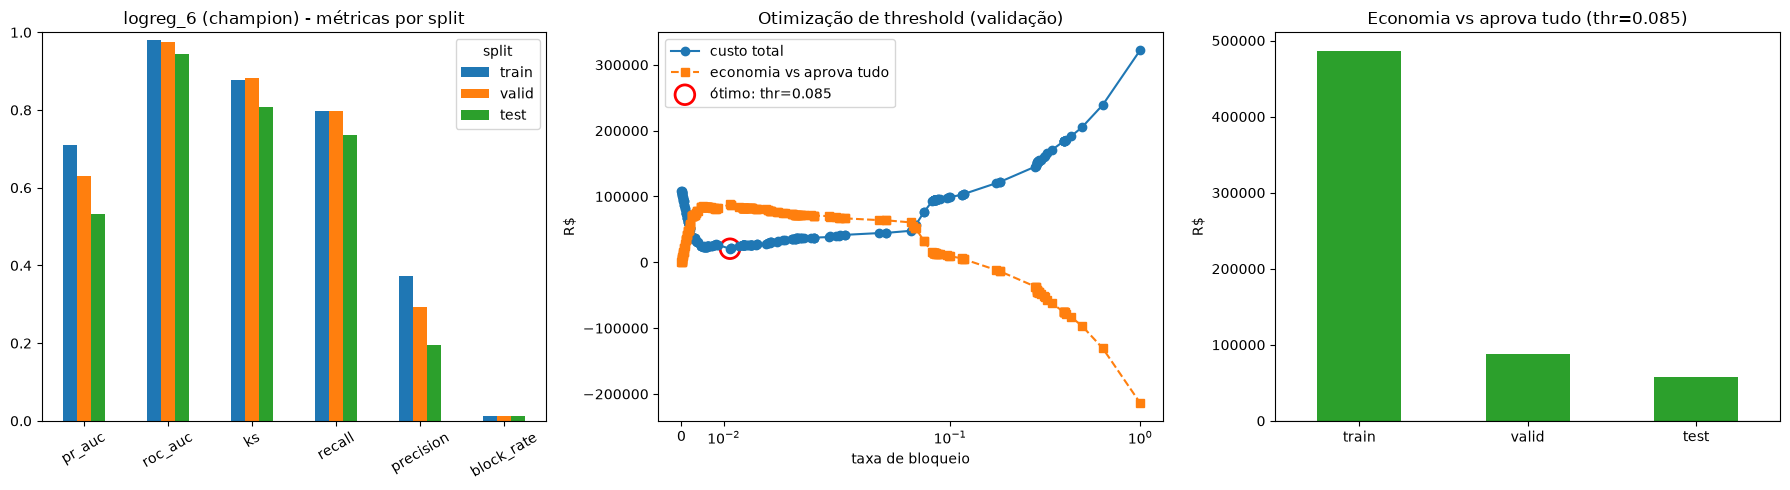

In [6]:
curves = {name: threshold_cost_curve(data[target], scores[name], data["amount"], **pnl_params)
          for name, data in splits.items()}
assert np.isclose(optimal_threshold(curves["valid"]), threshold)

plot_model_results(metrics, curves["valid"], model_name="logreg_6 (champion)")
plt.show()

O threshold é escolhido na validação e aplicado no teste. Comparando com o ótimo *ex post* de cada split, dá para ver quanto custa não conhecer o futuro:

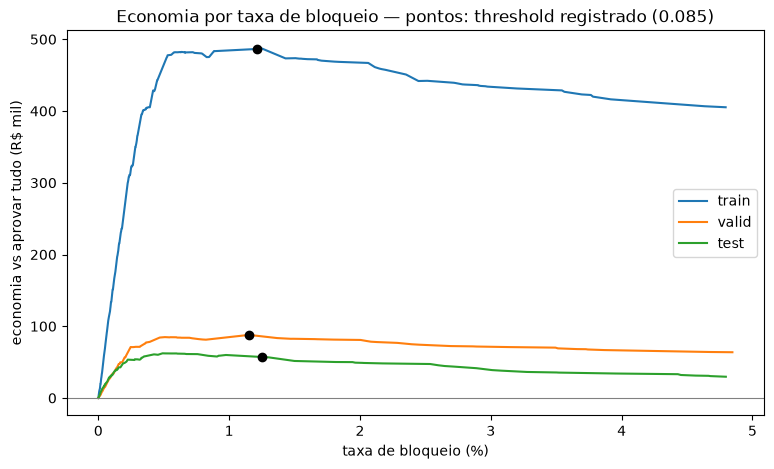

,threshold_otimo_ex_post,economia_no_threshold,economia_otima_ex_post,perda_vs_otimo
train,0.080151,486496.786,487828.689,1.331903e+03
valid,0.085034,87895.380,87895.380,-4.365575e-11
test,0.263361,57192.190,62291.956,5.099766e+03


In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, curve in curves.items():
    c = curve[curve["block_rate"] <= 0.05]
    ax.plot(c["block_rate"] * 100, c["savings_vs_approve_all"] / 1e3, label=name)
    at_thr = curve[curve["threshold"] >= threshold].iloc[-1]
    ax.scatter(at_thr["block_rate"] * 100, at_thr["savings_vs_approve_all"] / 1e3, color="black", zorder=3)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("taxa de bloqueio (%)")
ax.set_ylabel("economia vs aprovar tudo (R$ mil)")
ax.set_title(f"Economia por taxa de bloqueio — pontos: threshold registrado ({threshold:.3f})")
ax.legend()
plt.show()

summary = pd.DataFrame({
    name: {
        "threshold_otimo_ex_post": optimal_threshold(c),
        "economia_no_threshold": metrics.loc[name, "savings_vs_approve_all"],
        "economia_otima_ex_post": c["savings_vs_approve_all"].max(),
    } for name, c in curves.items()
}).T
summary["perda_vs_otimo"] = summary["economia_otima_ex_post"] - summary["economia_no_threshold"]
summary

**Leitura da curva de custo**

* O threshold registrado (**0,085**) é o mínimo de custo na validação. Ele bloqueia ~1,1–1,3% das transações em todos os splits e recupera 80% das fraudes na validação e 74% no teste.
* No teste, a economia frente a aprovar tudo é de **R$ 57,2 mil**. O ótimo *ex post* do teste fica num threshold mais alto (0,26) e economizaria R$ 62,3 mil. A diferença de **~R$ 5,1 mil (8%)** é o custo de escolher o corte sem conhecer o futuro.
* O ótimo do teste mais alto reflete a queda da taxa de fraude (0,42% na validação → 0,33% no teste): com menos fraude na base, o mesmo score carrega mais falsos positivos, e compensa ser mais conservador. Vale monitorar a taxa de fraude e recalibrar o threshold periodicamente.
* A curva é plana perto do ótimo. Erros moderados no threshold custam pouco, o que dá margem para ajustar o corte por critérios operacionais (ex.: capacidade de revisão manual).

## Coeficientes

Na regressão logística, cada coeficiente $\beta$ é o efeito aditivo da variável no **log-odds** de fraude. A forma mais legível é a razão de chances (*odds ratio*) $e^{\beta}$: o fator pelo qual as chances de fraude se multiplicam quando a variável aumenta em uma unidade (ou quando a flag passa de 0 para 1), mantidas as demais.

In [8]:
coefs = pd.DataFrame({"coef": np.append(model.intercept_, model.coef_.ravel())},
                     index=["intercept", *features])
coefs["odds_ratio"] = np.exp(coefs["coef"])
coefs.loc["intercept", "odds_ratio"] = np.nan

X_train = train[features].astype(float)
coefs.loc[features, "media_treino"] = X_train.mean().values
coefs.loc[features, "max_treino"] = X_train.max().values
coefs

,coef,odds_ratio,media_treino,max_treino
intercept,-9.593144,NaN,NaN,NaN
high_amount,2.480428,11.946377,0.049830,1.0
night,2.988251,19.850941,0.234228,1.0
risk_vertical,0.112786,1.119392,0.313219,1.0
txns_prev_1h,0.254171,1.289392,0.189282,6.0
amount_to_customer_median_ratio_30d_gt_5,1.635841,5.133774,0.046795,1.0
n_high_prev_24h,1.519880,4.571675,0.213290,11.0


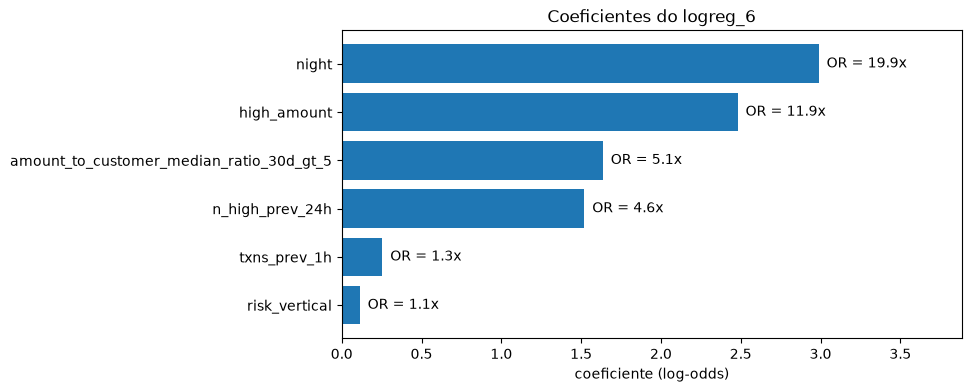

Probabilidade com todas as variáveis = 0: 0.0068%
Taxa de fraude no treino: 0.5683%


In [9]:
c = coefs.drop("intercept").sort_values("coef")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(c.index, c["coef"], color="tab:blue")
for y, (b, o) in enumerate(zip(c["coef"], c["odds_ratio"])):
    ax.text(b + 0.05, y, f"OR = {o:.1f}x", va="center")
ax.set_xlabel("coeficiente (log-odds)")
ax.set_title("Coeficientes do logreg_6")
ax.set_xlim(0, c["coef"].max() * 1.3)
plt.show()

base_p = 1 / (1 + np.exp(-model.intercept_[0]))
print(f"Probabilidade com todas as variáveis = 0: {base_p:.4%}")
print(f"Taxa de fraude no treino: {train[target].mean():.4%}")

Para dar escala aos coeficientes, alguns perfis típicos e seus scores:

In [10]:
profiles = pd.DataFrame([
    {"perfil": "base (dia, valor baixo)"},
    {"perfil": "valor > 200", "high_amount": 1},
    {"perfil": "valor > 200 + noite", "high_amount": 1, "night": 1},
    {"perfil": "valor > 200 + noite + 5x mediana", "high_amount": 1, "night": 1,
     "amount_to_customer_median_ratio_30d_gt_5": 1},
    {"perfil": "noite + 2 altas nas últimas 24h", "night": 1, "n_high_prev_24h": 2},
    {"perfil": "valor > 200 + noite + 2 altas 24h", "high_amount": 1, "night": 1, "n_high_prev_24h": 2},
]).set_index("perfil").reindex(columns=features).fillna(0)
profiles["score"] = model.predict_proba(profiles[features])[:, 1]
profiles["bloqueia"] = profiles["score"] >= threshold
profiles[["score", "bloqueia"]]

,score,bloqueia
perfil,,
"base (dia, valor baixo)",0.000068,False
valor > 200,0.000814,False
valor > 200 + noite,0.015915,False
valor > 200 + noite + 5x mediana,0.076660,False
noite + 2 altas nas últimas 24h,0.027515,False
valor > 200 + noite + 2 altas 24h,0.252617,True


**Leitura dos coeficientes**

* **Intercepto (−9,6):** uma transação diurna, de valor baixo e sem histórico de risco tem probabilidade de fraude de ~0,007%, quase 100x abaixo da taxa média do treino (0,57%). O modelo concentra o risco em poucos perfis.
* **`night` (OR ≈ 20x) e `high_amount` (OR ≈ 12x)** são os dois maiores efeitos. Sozinhos, porém, não bastam para bloquear: uma transação alta e noturna fica em ~1,6%, abaixo do threshold de 8,5%. É preciso algum sinal adicional de comportamento.
* **`amount_to_customer_median_ratio_30d_gt_5` (OR ≈ 5x):** valor muito fora do padrão do próprio cliente. Somado a valor alto e noite, leva o score a ~7,6%, ainda logo abaixo do corte.
* **`n_high_prev_24h` (OR ≈ 4,6x por transação):** é a única variável de contagem com efeito forte, e o efeito se acumula. Duas transações altas nas últimas 24h multiplicam as chances por ~21x, e combinadas com valor alto e noite levam o score a ~25%, bem acima do corte. É ela que transforma o padrão de "rajada" em bloqueio e explica o salto de performance do run 6.
* **`txns_prev_1h` (OR ≈ 1,3x) e `risk_vertical` (OR ≈ 1,1x):** efeitos pequenos depois que `n_high_prev_24h` entra no modelo. Os dois perderam peso entre os runs 4 e 6, sinal de que parte da informação deles é redundante com o histórico de 24h. São candidatos a remoção numa versão mais enxuta, a confirmar com a checagem de multicolinearidade do notebook 2.
* Todos os coeficientes são positivos e com sinal coerente com a EDA: nenhuma variável "protege" contra fraude, o que facilita explicar uma decisão de bloqueio como a soma de fatores de risco.